(crispr_screens)=

# Pooled CRISPR screens

A pooled CRISPR screen gives each cell a guide RNA that knocks out one gene, then sequences the cell, so one experiment measures many perturbations. The analysis decides which guide each cell carries, checks that each perturbation changed its target gene, separates the cells that kept the gene's function, and asks what each perturbation changed.

This page analyzes the ECCITE-seq screen of @Papalexi_2021, which looked for regulators of PD-L1, the immune checkpoint protein encoded by CD274. THP-1 cells, a human acute myeloid leukemia line, were transduced with guides against 26 genes and with non-targeting control guides, then stimulated with interferon gamma (IFN-γ), TGF-β1 and decitabine to induce PD-L1. ECCITE-seq measured four things in each cell: RNA, the guide it carries, a hashtag antibody that marks its replicate, and four surface proteins, PD-L1 among them. The page ends where the paper did: cells that lost an IFN-γ pathway gene lower PD-L1 protein, while cells that carry the same guides but escaped the edit look like controls.

## Download the screen

GEO series [GSE153056](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE153056) holds the screen as four count tables, one per measurement, and the authors' cell metadata; the five files total 66 MB. The tables hold the 20,729 cells that the authors kept after quality control, hashtag demultiplexing and guide assignment, so this page checks those decisions rather than making them from raw droplets.

The example uses a temporary directory. Use a project directory instead if you want to keep the downloaded files and the store after closing the notebook.

In [1]:
# Download and verify the published files.
import gzip
import hashlib
import shutil
import warnings
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlopen

# Read the count tables and assemble the store.
import anndata
import numpy as np
import pandas as pd
from scipy import sparse
import cytearc
from cytearc.plotting import FeatureRef
from cytearc.storage.count_matrix import CountMatrixPolicy

# Display the diagnostic figures.
import matplotlib.pyplot as plt

# Keep routine logs and progress bars out of the results.
cytearc.configure_output(level="WARNING", progress=False)

# Keep this example's downloads and store together.
work = TemporaryDirectory()
output_dir = Path(work.name)

Started: 2026-10-30T21:58:47.294354Z | Wall time: 2.301 s

In [2]:
# Pin the five GEO files so that a changed download cannot alter the example silently.
geo = "https://ftp.ncbi.nlm.nih.gov/geo"
sources = {
    "rna": (
        f"{geo}/samples/GSM4633nnn/GSM4633614/suppl/"
        "GSM4633614_ECCITE_cDNA_counts.tsv.gz",
        "2acb14a10b95f9b39536d0aec42896f30f6256332ccd336a2b01d037316b6080",
    ),
    "protein": (
        f"{geo}/samples/GSM4633nnn/GSM4633615/suppl/"
        "GSM4633615_ECCITE_ADT_counts.tsv.gz",
        "e0f6f1dd1fc36d29580a5f5cf13f0d21a98a9b0d1ebb9479ed6291a355d4cb7f",
    ),
    "hashtag": (
        f"{geo}/samples/GSM4633nnn/GSM4633616/suppl/"
        "GSM4633616_ECCITE_HTO_counts.tsv.gz",
        "269069672fc09710136ea693e7702295c02f6c38aa824933eb4529a4c75944f5",
    ),
    "guide": (
        f"{geo}/samples/GSM4633nnn/GSM4633618/suppl/"
        "GSM4633618_ECCITE_GDO_counts.tsv.gz",
        "93c67d2a92fb98fcbdfe28b9a0ac94ffee08da035b112d5452ceaeacdcb7570a",
    ),
    "metadata": (
        f"{geo}/series/GSE153nnn/GSE153056/suppl/GSE153056_ECCITE_metadata.tsv.gz",
        "7059b0cb857dc344e6bb53dbdc5ccadccb25bb069372ed6f45eff46b7e992a76",
    ),
}
paths = {}
for name, (url, expected_digest) in sources.items():
    path = output_dir / url.rsplit("/", 1)[1]

    # Copy the response in blocks without holding the file in memory.
    with urlopen(url, timeout=60) as response, path.open("wb") as destination:
        shutil.copyfileobj(response, destination)

    # Reject a file whose contents differ from the verified source.
    with path.open("rb") as source:
        actual_digest = hashlib.file_digest(source, "sha256").hexdigest()
    if actual_digest != expected_digest:
        raise ValueError(f"Checksum mismatch for {path.name}")
    paths[name] = path

# Show the size of each completed download.
pd.Series(
    {name: path.stat().st_size / 1_000_000 for name, path in paths.items()},
    name="Downloaded MB",
).round(2)

rna         64.14
protein      0.20
hashtag      0.17
guide        0.34
metadata     1.06
Name: Downloaded MB, dtype: float64

Started: 2026-10-30T21:58:49.597578Z | Wall time: 6.303 s

## Read the count tables

Each table has features along rows and cells along columns. Cell barcodes start with their 10x lane, `l1_` to `l8_`, and every file lists the same cells in the same order. The guide table counts 111 guides: 9 non-targeting (NT) guides, 3 against PD-L1, 1 against eGFP, and 3 or 4 against each of 25 other genes. The protein table counts four antibodies, against CD86, PD-L1, PD-L2 and CD366.

In [3]:
# Read the three small tables with cells as rows.
guide_counts = pd.read_csv(paths["guide"], sep="\t", index_col=0).T
hashtag_counts = pd.read_csv(paths["hashtag"], sep="\t", index_col=0).T
protein_counts = pd.read_csv(paths["protein"], sep="\t", index_col=0).T

# Read the authors' calls and quality metrics for each cell.
authors = pd.read_csv(paths["metadata"], sep="\t", index_col=0)

# Check that every table lists the same cells in the same order.
cells = guide_counts.index
for table in (hashtag_counts, protein_counts, authors):
    if not table.index.equals(cells):
        raise ValueError("The tables list different cells")

# Show the size of each table.
pd.DataFrame(
    {
        "Cells": [
            len(table) for table in (guide_counts, hashtag_counts, protein_counts)
        ],
        "Features": [
            table.shape[1] for table in (guide_counts, hashtag_counts, protein_counts)
        ],
    },
    index=["Guides", "Hashtags", "Proteins"],
)

,Cells,Features
Guides,20729,111
Hashtags,20729,12
Proteins,20729,4


Started: 2026-10-30T21:58:55.902693Z | Wall time: 1.753 s

The guide table needs one correction. None of its entries is 0: each of the 111 guides has at least one count in every cell, and 93% of the entries are exactly 1, while a cell should hold no molecule of most guides. The table therefore stores each count plus one. The authors' rule shows the same offset: they assigned each cell its top guide when it had at least five counts, and the smallest count of a cell's top guide in the table is 6. Subtract one to restore the counts.

In [4]:
# Measure the smallest entries, and each cell's top guide count.
guide_values = guide_counts.to_numpy()
evidence = pd.Series(
    {
        "Smallest entry": guide_values.min(),
        "Entries equal to 1 (%)": round(100 * float((guide_values == 1).mean()), 1),
        "Smallest top-guide count of a cell": guide_values.max(axis=1).min(),
    },
    name="Guide table",
    dtype=object,
)

# Restore the counts by removing the added one.
guide_counts = guide_counts - 1
evidence

Smallest entry                           1
Entries equal to 1 (%)                92.9
Smallest top-guide count of a cell       6
Name: Guide table, dtype: object

Started: 2026-10-30T21:58:57.657680Z | Wall time: 0.021 s

The RNA table has 18,649 genes and about 70 million nonzero counts, which take about 3 GB as a dense table. Read one gene at a time and keep only its nonzero counts.

In [5]:
# Read the RNA table one gene at a time, keeping each gene's nonzero counts.
with gzip.open(paths["rna"], "rt") as source:
    rna_cells = [cell.strip('"') for cell in next(source).rstrip("\n").split("\t")[1:]]
    genes, positions, counts, offsets = [], [], [], [0]
    for line in source:
        gene, values = line.split("\t", 1)
        gene_counts = np.fromstring(values, sep="\t", dtype=np.int64)
        if gene_counts.size != len(rna_cells):
            raise ValueError(f"Unexpected number of RNA counts for {gene}")
        nonzero = np.flatnonzero(gene_counts)
        genes.append(gene.strip('"'))
        positions.append(nonzero.astype(np.int32))
        counts.append(gene_counts[nonzero].astype(np.int32))
        offsets.append(offsets[-1] + nonzero.size)

# Check that the RNA table lists the same cells as the other tables.
if rna_cells != list(cells):
    raise ValueError("The RNA table lists different cells")

# Build a sparse matrix with cells as rows.
rna_counts = sparse.csr_matrix(
    (np.concatenate(counts), np.concatenate(positions), np.asarray(offsets)),
    shape=(len(genes), len(cells)),
).T.tocsr()
del positions, counts

# Show the size of the RNA table.
pd.Series(
    {"Genes": rna_counts.shape[1], "Nonzero counts": rna_counts.nnz}, name="RNA table"
)

Genes                18649
Nonzero counts    69529049
Name: RNA table, dtype: int64

Started: 2026-10-30T21:58:57.680266Z | Wall time: 11.650 s

## Build one store with four assays

A CyteArc store keeps each measurement as an assay, and all assays share one table of cells. Combine the four tables into one AnnData whose `feature_types` column names each feature's assay, and import it with `assay_split_key`. The assay names `RNA`, `CRISPR`, `HTO` and `ADT` declare each assay's type, so CyteArc reads the guide counts as a CRISPR assay. Feature IDs must be unique across the file, and CD86 names both a gene and an antibody, so the antibodies get IDs with the suffix `-protein`, while their names stay as the authors wrote them. Each cell's lane, the prefix of its barcode, becomes a cell column.

In [6]:
# Name each feature's assay, and give the antibodies IDs that no gene uses.
feature_types = (
    ["RNA"] * len(genes)
    + ["CRISPR"] * guide_counts.shape[1]
    + ["HTO"] * hashtag_counts.shape[1]
    + ["ADT"] * protein_counts.shape[1]
)
feature_names = (
    genes
    + list(guide_counts.columns)
    + list(hashtag_counts.columns)
    + list(protein_counts.columns)
)
feature_ids = feature_names[: -protein_counts.shape[1]] + [
    f"{name}-protein" for name in protein_counts.columns
]

# Combine the four tables, as 32-bit counts, into one AnnData with each cell's lane.
combined = anndata.AnnData(
    X=sparse.hstack(
        [rna_counts]
        + [
            sparse.csr_matrix(table.to_numpy(dtype=np.int32))
            for table in (guide_counts, hashtag_counts, protein_counts)
        ],
        format="csr",
    ),
    obs=pd.DataFrame({"lane": cells.str.split("_").str[0]}, index=cells),
    var=pd.DataFrame(
        {"feature_name": feature_names, "feature_types": feature_types},
        index=feature_ids,
    ),
)

# Write the AnnData, then release the tables it copied.
h5ad_path = output_dir / "papalexi_eccite.h5ad"
combined.write_h5ad(h5ad_path)
del combined, rna_counts

Started: 2026-10-30T21:59:09.333492Z | Wall time: 1.272 s

The import's default count layout suits large matrices and needs more memory than the 4 GB that this page allows, so pass the smaller layout that fits; a store of this size reads fast in either layout.

In [7]:
# Import the four assays into one store.
store_path = output_dir / "papalexi_eccite.zarr"
cytearc.H5adToZarr(
    cytearc.H5adReader(str(h5ad_path), feature_name_key="feature_name"),
    str(store_path),
    assay_split_key="feature_types",
    nthreads=4,
    mem_budget="4G",
    policy=CountMatrixPolicy(unitBytes=31_250_000, chunkBytes=3_125_000),
).dump()

# Open the store with RNA as the default assay.
ds = cytearc.DataStore(
    str(store_path), default_assay="RNA", nthreads=4, mem_budget="4G"
)
ds

DataStore has 20729 (20729) cells with 4 assays: ADT CRISPR HTO RNA
   Cell metadata:
            'I', 'ids', 'names', 'ADT_nCounts', 'ADT_nFeatures', 
            'CRISPR_nCounts', 'CRISPR_nFeatures', 'HTO_nCounts', 'HTO_nFeatures', 'RNA_nCounts', 
            'RNA_nFeatures', 'RNA_percentMito', 'RNA_percentRibo', 'lane'
   ADT assay has 4 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'feature_types', 
            'nCells'
   CRISPR assay has 111 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'feature_types', 
            'nCells'
   HTO assay has 12 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'feature_types', 
            'nCells'
   RNA assay has 18649 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'feature_types', 
            'nCells'

Started: 2026-10-30T21:59:10.608466Z | Wall time: 11.339 s

## Record the replicates and the guide targets

The cells come from three replicates, each stained with its own hashtag antibody before the replicates were pooled. The deposit holds only the singlets that the authors kept, so most hashtags have no background cells left to fit, and calling the hashtags again would not reproduce the authors' calls; [](hto_demultiplexing.ipynb) shows how to call hashtags from the counts of every droplet. Record the hashtag that the authors called as each cell's replicate, and check it against the hashtag counts.

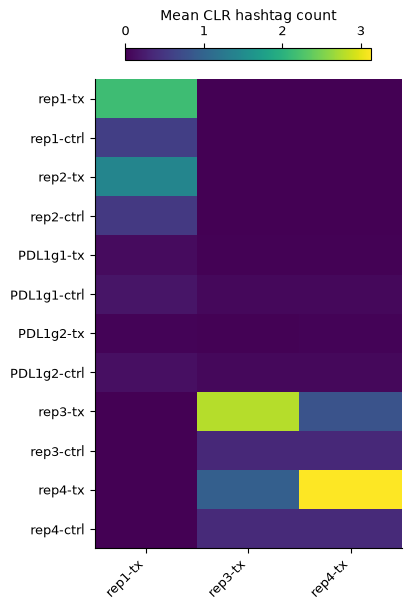

Started: 2026-10-30T21:59:21.949502Z | Wall time: 0.452 s

In [8]:
# Align the authors' metadata with the store's cells.
authors = authors.loc[ds.cells.fetch_all("ids")]

# Record the hashtag that the authors called in each cell as its replicate.
ds.cells.insert("replicate", authors["MULTI_ID"].to_numpy())

# Compare the mean normalized count of each hashtag between the replicates.
hashtags = ds.HTO.feats.fetch_all("ids").tolist()
heatmap = ds.plots.matrixplot(
    features=hashtags,
    group_by="replicate",
    from_assay="HTO",
    figsize=(4, 6),
    show=False,
)

# Label the color scale for the hashtag counts.
heatmap.axes["matrixplot"].images[0].colorbar.set_label("Mean CLR hashtag count")
plt.show()

Each replicate carries its own hashtag. Lanes 1 to 4 hold replicate `rep1-tx` and lanes 5 to 8 the other two, so a replicate also shows a little of the other hashtags pooled in its lanes, and none of the rest. The `-ctrl` hashtags marked unstimulated cells, which the authors left out of these tables.

Each guide ID names its target gene, followed by `g` and the guide's number, such as `IRF1g4`, and `NT` names the non-targeting guides. Write each guide's target as the guide assay's `target_gene_name` column, which `perturbation.labels` reads, and as `target_gene_id`, which the efficiency, association and profile steps use to find the target in the RNA assay. This store identifies genes by their symbols, so a target's symbol is also its RNA feature ID. The PD-L1 guides target CD274, PD-L1's gene.

In [9]:
# Read each guide's target from its ID, and name PD-L1 by its gene symbol.
guides = ds.CRISPR.feats.fetch_all("ids")
targets = (
    pd.Series(guides).str.replace(r"g\d+$", "", regex=True).replace({"PDL1": "CD274"})
)

# Store the targets as the guide assay's target columns.
ds.CRISPR.feats.insert("target_gene_name", targets.to_numpy())
ds.CRISPR.feats.insert("target_gene_id", targets.to_numpy())

# Count the guides of each target.
targets.value_counts().rename("Guides").to_frame().T

,NT,ATF2,BRD4,CAV1,CD86,ETV7,IFNGR1,IFNGR2,IRF1,IRF7,...,STAT1,STAT2,STAT3,STAT5A,TNFRSF14,UBE2L6,CUL3,CMTM6,CD274,eGFP
Guides,9,4,4,4,4,4,4,4,4,4,...,4,4,4,4,4,4,3,3,3,1


Started: 2026-10-30T21:59:22.403588Z | Wall time: 0.041 s

## Map the expression of every cell

Run the RNA recipe over all cells. The authors already removed low-quality cells, so skip filtering, and keep 2,000 highly variable genes and 40 principal components, as the authors did. The screen needs no clusters, doublet scores or markers. Snapshot the replicate and the lane, so that the run keeps them with its cells.

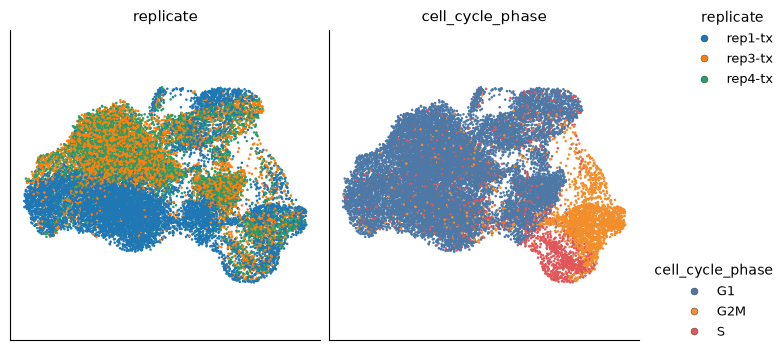

Started: 2026-10-30T21:59:22.446635Z | Wall time: 68.664 s

In [10]:
# Analyze RNA over all cells: variable genes, PCA, graph, and UMAP.
rna = ds.pipeline.rna(
    label="rna",
    filtering=False,
    hvg={"top_n": 2000},
    pca={"dims": 40},
    leiden=False,
    doublets=False,
    markers=False,
    snapshot_columns=["replicate", "lane"],
)

# Color the map by replicate and by cell-cycle phase.
ds.plots.embedding(run=rna, color_by=["replicate", "cell_cycle_phase"], n_columns=2)

Replicate and cell-cycle phase shape the map. The paper found the same, and it is why Mixscape, below, compares each cell with control cells of similar state.

## Call guides

Every cell holds a few molecules of guides it does not carry, ambient molecules from other cells, so a nonzero count is not a call. `perturbation.call_guides` fits each guide's counts with a Poisson background plus a Gaussian for the cells that carry the guide, as @Replogle_2022 did, and calls a guide in the cells whose counts reach the fitted threshold. Call guides over the RNA run's cells, so that the labels below share the run's cells and can color its map. Print the warnings: they name the guides whose fit calls no cell.

In [11]:
# Call guides over the RNA run's cells, keeping the warnings.
cells = rna["analysis_cell_selection"]
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    calls = ds.perturbation.call_guides(cells)

# Print the guides whose fit calls no cell.
for warning in caught:
    print(warning.message)

# Count the cells with no called guide, one guide, and several guides.
guide_calls = ds.perturbation.load_guide_calls(calls).cells
guide_calls["call"].where(
    guide_calls["call"].isin(["Negative", "Multiple"]), "One guide"
).value_counts()

4 of 111 guide fits call no cell: 1 have no cell with a UMI of the guide, 2 have too few cells or counts to fit, 1 have no admissible fit. For example 'eGFPg1', 'PDL1g2', 'PDL1g3', 'MYCg4'. perturbation.load_guide_thresholds lists every status.


call
One guide    18330
Multiple      1806
Negative       593
Name: count, dtype: int64

Started: 2026-10-30T22:00:31.112640Z | Wall time: 4.992 s

No cell holds a UMI of the eGFP guide, two PD-L1 guides have too few cells or counts to fit, and MYCg4's counts admit no fit. Of the 20,729 cells, 18,330 carry one called guide, 1,806 several, and 593 none. The plot shows how many guides each cell carries, how many cells carry each guide, and the share of a cell's guide UMIs that its top guide holds.

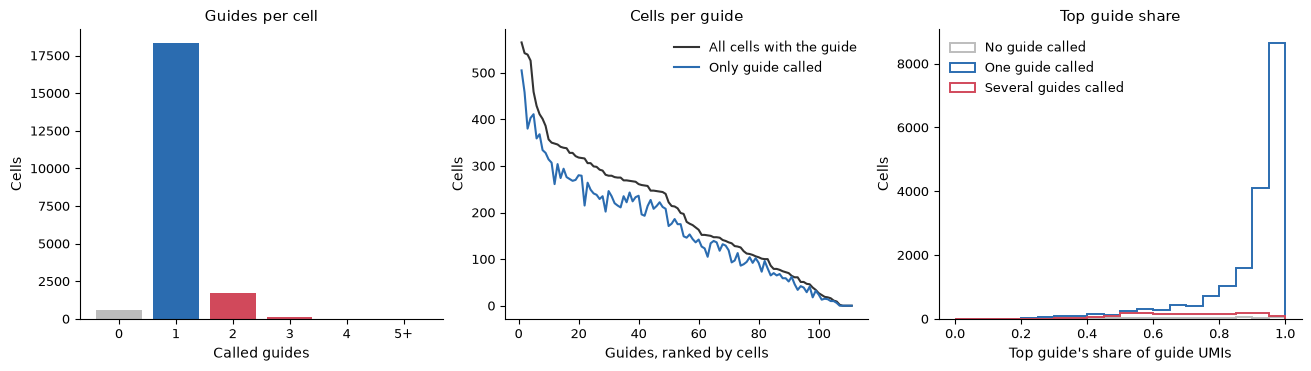

Started: 2026-10-30T22:00:36.105988Z | Wall time: 0.471 s

In [12]:
# Plot guides per cell, cells per guide, and each cell's top-guide share.
ds.plots.guide_calls(calls)

Inspect a fit to see where its threshold falls. The histogram counts the cells by their UMIs of the guide; the cells above the threshold are called, and the curve is the fitted probability that a cell carries the guide.

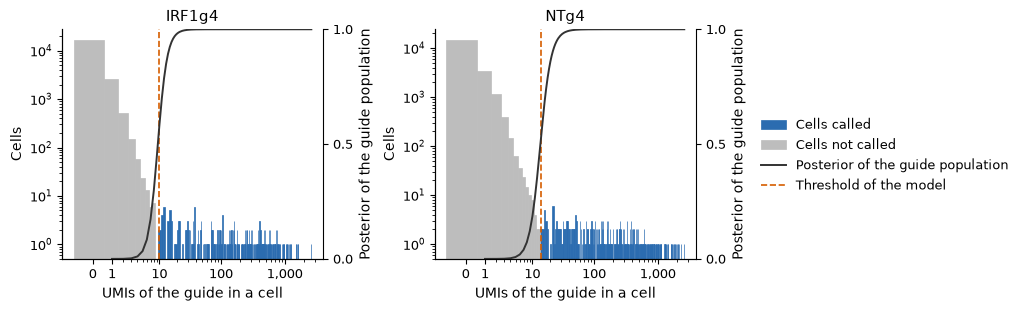

Started: 2026-10-30T22:00:36.578684Z | Wall time: 1.225 s

In [13]:
# Show the fit of a targeting guide and of a non-targeting guide.
ds.plots.guide_thresholds(calls, guides=["IRF1g4", "NTg4"])

Lanes 1 to 4 have more guide UMIs per cell than lanes 5 to 8, and `sample_column="lane"` fits each lane separately. Each lane, though, holds about 25 cells of a typical guide. Compare the two choices on the calls they make.

In [14]:
# Fit each guide in each lane separately; the table below counts the failed fits.
with warnings.catch_warnings(record=True):
    warnings.simplefilter("always")
    per_lane = ds.perturbation.call_guides(cells, sample_column="lane")

# Compare the fits that call no cell and the calls of the two choices.
comparison = {}
for name, ref in {
    "One fit per guide": calls,
    "One fit per guide and lane": per_lane,
}.items():
    fits = ds.perturbation.load_guide_thresholds(ref).table
    called = ds.perturbation.load_guide_calls(ref).cells["call"]
    comparison[name] = {
        "Fits": len(fits),
        "Fits that call no cell": int((fits["status"] != "fitted").sum()),
        "Cells with one guide": int((~called.isin(["Negative", "Multiple"])).sum()),
        "Cells with several guides": int((called == "Multiple").sum()),
        "Cells with no guide": int((called == "Negative").sum()),
    }
pd.DataFrame(comparison)

,One fit per guide,One fit per guide and lane
Fits,111,888
Fits that call no cell,4,58
Cells with one guide,18330,17093
Cells with several guides,1806,3300
Cells with no guide,593,336


Started: 2026-10-30T22:00:37.805368Z | Wall time: 0.564 s

Fitting each lane leaves 58 of 888 fits without a call and puts other thresholds among the ambient counts, which nearly doubles the cells with several guides. Keep one fit per guide.

The authors assigned each cell its top guide. Compare the cells with one called guide with their assignment.

In [15]:
# Compare each single-guide call with the authors' guide.
called = guide_calls["call"]
single = ~called.isin(["Negative", "Multiple"])
agreement = called[single] == authors.loc[called.index[single], "guide_ID"]
pd.Series(
    {
        "Cells with one called guide": int(single.sum()),
        "Same guide as the authors (%)": round(100 * agreement.mean(), 2),
    },
    name="Guide calls",
    dtype=object,
)

Cells with one called guide      18330
Same guide as the authors (%)    99.69
Name: Guide calls, dtype: object

Started: 2026-10-30T22:00:38.372156Z | Wall time: 0.023 s

## Label cells by target

`perturbation.labels` labels each cell by the gene that its called guides target. Name the control targets explicitly; CyteArc never guesses them. Cells with control guides only are labelled `control`, cells with guides of one gene take the gene's name, also when they carry control guides too, cells with guides of two or more genes are `Multiple`, and cells without a called guide are `Negative`.

In [16]:
# Label each cell by its target, with the non-targeting guides as controls.
labels = ds.perturbation.labels(calls, controls=["NT"])
labelled = ds.perturbation.load_labels(labels).cells

# Count the cells of each label.
labelled["label"].value_counts().rename("Cells").to_frame().T

label,control,Multiple,IFNGR2,IFNGR1,ATF2,CD86,IRF1,JAK2,TNFRSF14,MARCH8,...,PDCD1LG2,UBE2L6,IRF7,STAT3,STAT1,BRD4,CUL3,MYC,SPI1,CD274
Cells,2164,1397,1122,1078,1062,1057,997,908,907,877,...,572,489,479,457,399,333,239,96,45,2


Started: 2026-10-30T22:00:38.397434Z | Wall time: 0.177 s

A cell with several called guides keeps one label when its guides target one gene, or one gene and the controls. Count those cells, and compare the labels with the authors' target of each cell.

In [17]:
# Find the cells with several guides that got one target or the control label.
merged = (labelled["guide_label"] == "Multiple") & (labelled["label"] != "Multiple")

# Compare the labels with the authors' targets, which name the control cells NT.
authors_label = authors["gene"].replace({"NT": "control"}).reindex(labelled.index)
compared = ~labelled["label"].isin(["Negative", "Multiple"])
differs = compared & (labelled["label"] != authors_label)

# Count the disagreements, and those where the authors labelled a control.
pd.Series(
    {
        "Cells with several guides and one label": int(merged.sum()),
        "Cells labelled by both": int(compared.sum()),
        "Same label as the authors (%)": round(100 * (1 - differs[compared].mean()), 1),
        "Different labels": int(differs.sum()),
        "Of these, a gene here and a control for the authors": int(
            (differs & (authors_label == "control")).sum()
        ),
    },
    name="Labels",
    dtype=object,
)

Cells with several guides and one label                  409
Cells labelled by both                                 18739
Same label as the authors (%)                           98.8
Different labels                                         218
Of these, a gene here and a control for the authors      171
Name: Labels, dtype: object

Started: 2026-10-30T22:00:38.576690Z | Wall time: 0.025 s

Most disagreements are cells that carry a control guide beside a gene's guide: CyteArc labels them by the gene, while the authors assigned the top guide, a control.

On the map, cells that lost IFNGR2 or JAK2 gather in one region, while cells of most other targets mix with the controls.

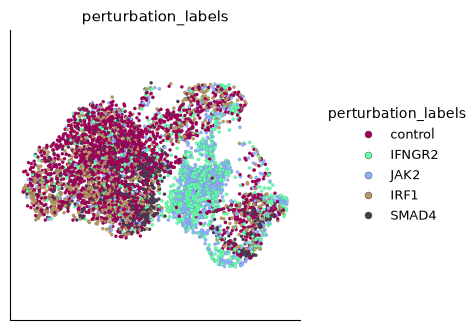

Started: 2026-10-30T22:00:38.603440Z | Wall time: 0.240 s

In [18]:
# Color the map by four targets and the control cells.
ds.plots.embedding(
    layout=rna["umap"],
    color_by=labels,
    groups=["control", "IFNGR2", "JAK2", "IRF1", "SMAD4"],
)

## Check each perturbation's target gene

`perturbation.efficiency` compares the expression of each target gene in the cells of its perturbation with the control cells. `remaining_fraction` is the share of the control expression left after scaling each cell to a common library size.

In [19]:
# Measure each target gene in its perturbed cells against the control cells.
efficiency = ds.perturbation.efficiency(labels)
measured = ds.perturbation.load_efficiency(efficiency).table

# Show the tested targets, strongest knockdown first.
columns = [
    "target",
    "n_cells",
    "control_mean_umi",
    "remaining_fraction",
    "adjusted_p_value",
]
measured.query("status == 'tested'").sort_values("remaining_fraction")[columns].round(3)

,target,n_cells,control_mean_umi,remaining_fraction,adjusted_p_value
20,STAT1,399,12.780,0.205,0.000
12,JAK2,908,2.784,0.214,0.000
21,STAT2,619,1.591,0.513,0.000
1,BRD4,333,1.583,0.559,0.000
6,CUL3,239,0.424,0.636,0.002
15,NFKBIA,708,3.142,0.641,0.000
19,SPI1,45,9.720,0.663,0.001
22,STAT3,457,2.314,0.664,0.000
9,IFNGR2,1122,5.464,0.667,0.000
2,CAV1,788,0.015,0.681,0.609


Started: 2026-10-30T22:00:38.845426Z | Wall time: 0.958 s

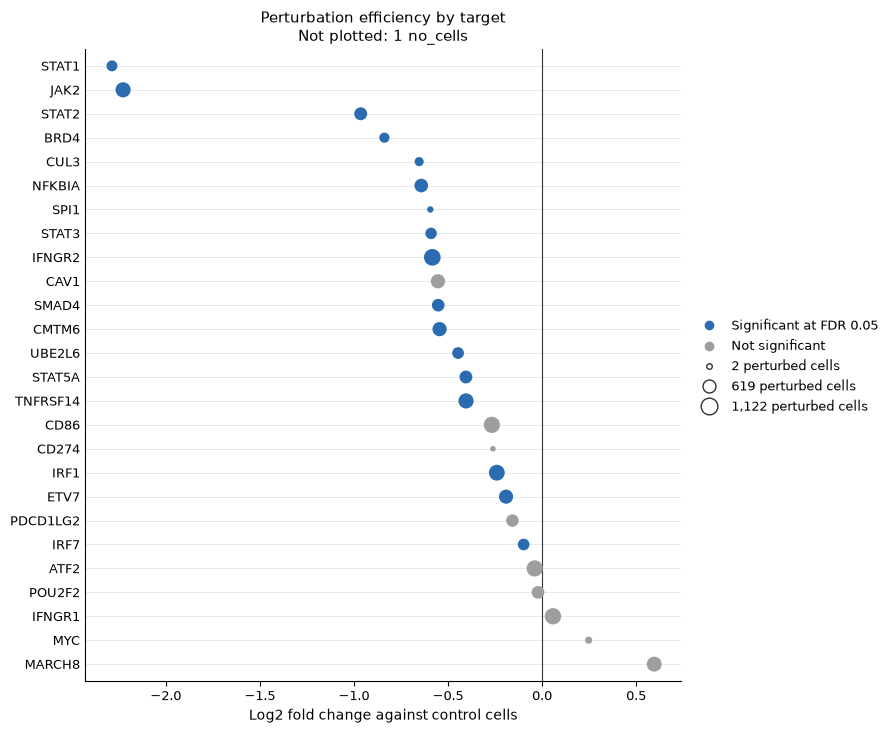

Started: 2026-10-30T22:00:39.805583Z | Wall time: 0.708 s

In [20]:
# Plot each target's log2 fold change against the control cells.
ds.plots.efficiency(efficiency)

STAT1 and JAK2 keep about a fifth of their control expression. IFNGR1 keeps all of it, although its cells change more than most in the steps below. A Cas9 knockout lowers its target's transcripts mainly when nonsense-mediated decay degrades the edited transcripts, so in a knockout screen a fraction near 1 does not show that the edit failed. The PD-L1 guides are called in two cells only, too few for any comparison.

## Rank perturbations by E-distance

The E-distance measures how far a perturbation moves the center of its cells from the control cells, here in the RNA run's 40 principal components, with a permutation test for each target [@Peidli_2024].

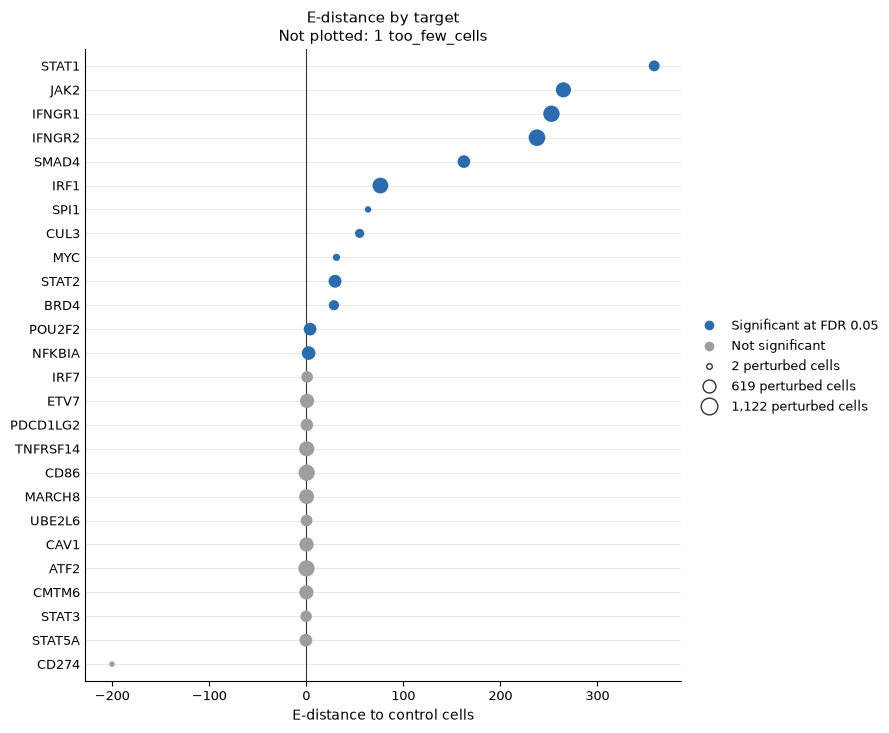

Started: 2026-10-30T22:00:40.514884Z | Wall time: 1.179 s

In [21]:
# Measure each target's E-distance from the control cells in the RNA run's PCA.
edistance = ds.perturbation.edistance(labels, rna["pca"])
distances = ds.perturbation.load_edistance(edistance).table

# Plot the E-distances, largest first.
ds.plots.edistance(edistance)

Thirteen targets move their cells significantly, led by STAT1, JAK2, IFNGR1 and IFNGR2. Their p-values sit at the floor that 1,000 permutations allow, so raise `n_permutations` to rank them by p-value.

## Separate knocked-out cells from escapers

Some cells that carry a targeting guide keep their target's function, for example after an in-frame edit, and look like controls. Mixscape finds them [@Papalexi_2021]. `perturbation.signature` subtracts from each cell the mean expression of its 20 nearest control cells in the same replicate, which removes what the cell shares with controls of similar state, such as its cell-cycle phase. `perturbation.mixscape` then finds the genes that each target changes, and fits each target's cells as a mixture of a knocked-out (KO) group and a non-perturbed (NP) group that looks like the controls.

In [22]:
# Compute each cell's perturbation signature within its replicate, over 40 PCs.
signature = ds.perturbation.signature(
    labels, rna["pca"], dims=40, sample_column="replicate"
)

# Classify each cell of each target as knocked out or not perturbed.
classes = ds.perturbation.mixscape(signature)
mixscape = ds.perturbation.load_mixscape(classes)

# Show each target's cells, KO cells and the genes that separate them.
targets_table = mixscape.targets.set_index("target")[
    ["status", "n_cells", "n_ko", "n_de_genes"]
]
targets_table["ko_share"] = (targets_table["n_ko"] / targets_table["n_cells"]).round(2)
targets_table.sort_values("ko_share", ascending=False)

,status,n_cells,n_ko,n_de_genes,ko_share
target,,,,,
SMAD4,fitted,586,493,1083,0.84
IFNGR1,fitted,1078,873,1515,0.81
JAK2,fitted,908,723,1516,0.80
STAT2,fitted,619,490,78,0.79
STAT1,fitted,399,309,1401,0.77
IFNGR2,fitted,1122,855,1560,0.76
IRF1,fitted,997,688,532,0.69
SPI1,fitted,45,21,6,0.47
BRD4,fitted,333,141,107,0.42


Started: 2026-10-30T22:00:41.695975Z | Wall time: 17.001 s

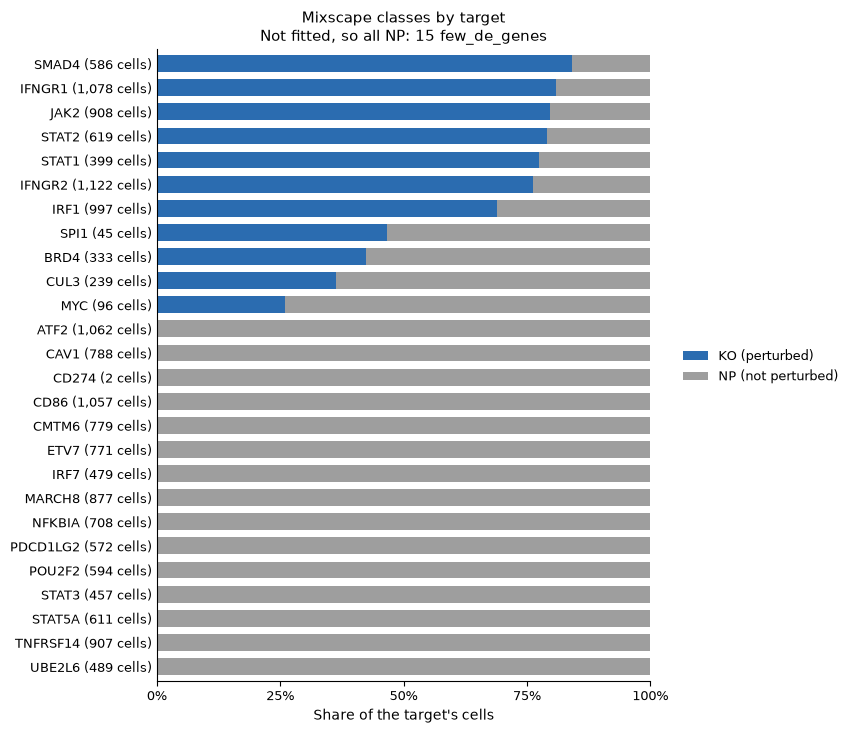

Started: 2026-10-30T22:00:58.698771Z | Wall time: 0.464 s

In [23]:
# Plot each target's shares of KO and NP cells.
ds.plots.mixscape(classes)

Mixscape finds KO cells for 11 targets, from 26% of MYC's cells to 84% of SMAD4's; the other 15 change too few genes to separate, so all their cells are NP. The paper reports the same split: 11 genes with 23% to 83% KO cells, 15 with none, and 75% for IFNGR2, against 76% here. The paper also found that IRF1's four guides knock out different shares of their cells, from 39% to 92%.

In [24]:
# Join each cell's class with its called guide, and keep the cells of one IRF1 guide.
by_guide = mixscape.cells.join(guide_calls["call"])
irf1 = by_guide[by_guide["call"].str.startswith("IRF1g")]

# Count each IRF1 guide's KO and NP cells.
shares = pd.crosstab(irf1["call"], irf1["global_class"])
shares["KO share"] = (shares["KO"] / shares.sum(axis=1)).round(2)
shares

global_class,KO,NP,KO share
call,,,
IRF1g1,149,119,0.56
IRF1g2,102,134,0.43
IRF1g3,146,40,0.78
IRF1g4,283,11,0.96


Started: 2026-10-30T22:00:59.164434Z | Wall time: 0.026 s

Here the four guides knock out 43% to 96% of their cells, so a target's KO share pools guides of different efficacy.

## Compare PD-L1 protein between knocked-out cells and escapers

The protein assay tests the classes on a measurement that Mixscape did not use. Compare PD-L1 protein, normalized by centered log ratio (CLR) across cells, between each target's KO and NP cells and the control cells, for the five targets whose loss lowered PD-L1 in the paper and the three whose loss raised it.

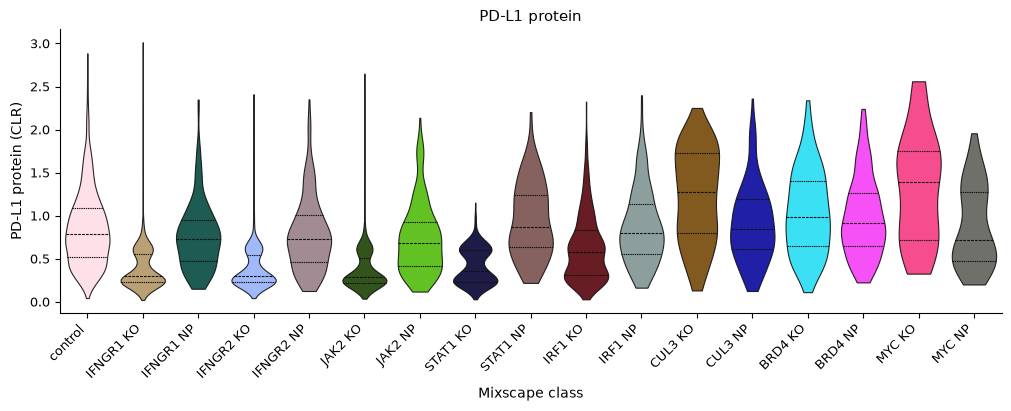

Started: 2026-10-30T22:00:59.192261Z | Wall time: 0.937 s

In [25]:
# Plot PD-L1 protein of the KO and NP cells of eight targets and of the control cells.
regulators = ["IFNGR1", "IFNGR2", "JAK2", "STAT1", "IRF1", "CUL3", "BRD4", "MYC"]
groups = ["control"] + [
    f"{target} {kind}" for target in regulators for kind in ("KO", "NP")
]
violins = ds.plots.distribution(
    FeatureRef("PDL1", assay="ADT", label="PD-L1 protein"),
    grouping=classes,
    groups=groups,
    max_points=0,
    figsize=(10, 4),
    show=False,
)

# Name the plotted measurement and the groups.
for ax in violins.axes.values():
    ax.set_xlabel("Mixscape class")
    ax.set_ylabel("PD-L1 protein (CLR)")
plt.show()

In [26]:
# Read each cell's normalized PD-L1 protein.
pdl1 = pd.Series(
    ds.get_cell_vals(from_assay="ADT", cell_key="I", k="PDL1"),
    index=ds.cells.fetch_all("ids"),
)

# Compare each class's median with the median of the control cells.
medians = pdl1.groupby(mixscape.cells["mixscape_class"]).median()
shift = (medians - medians["control"]).rename("PD-L1 median minus control")
shift.drop("control").reindex(groups[1:]).round(2).to_frame().T

mixscape_class,IFNGR1 KO,IFNGR1 NP,IFNGR2 KO,IFNGR2 NP,JAK2 KO,JAK2 NP,STAT1 KO,STAT1 NP,IRF1 KO,IRF1 NP,CUL3 KO,CUL3 NP,BRD4 KO,BRD4 NP,MYC KO,MYC NP
PD-L1 median minus control,-0.49,-0.07,-0.49,-0.06,-0.5,-0.1,-0.43,0.08,-0.21,0.0,0.48,0.06,0.2,0.12,0.6,-0.08


Started: 2026-10-30T22:01:00.131287Z | Wall time: 0.056 s

KO cells of IFNGR1, IFNGR2, JAK2, STAT1 and IRF1 hold less PD-L1 than the control cells, while their NP cells hold about as much as the controls: escapers keep the IFN-γ response. KO cells of CUL3, BRD4 and MYC hold more, as the paper found. CMTM6 is the exception that Mixscape cannot catch: its cells change no genes, so Mixscape calls them all NP, yet their PD-L1 median sits 0.23 below the controls, a change of the protein without an RNA counterpart.

In [27]:
# Keep the classes of at least 25 cells.
sizes = mixscape.cells["mixscape_class"].value_counts()
classes_shift = shift.drop("control")
classes_shift = classes_shift[sizes.reindex(classes_shift.index) >= 25]

# Show the eight classes with the lowest PD-L1 against the control cells.
classes_shift.sort_values().head(8).round(2).to_frame().T

mixscape_class,JAK2 KO,IFNGR2 KO,IFNGR1 KO,STAT1 KO,CMTM6 NP,IRF1 KO,JAK2 NP,MYC NP
PD-L1 median minus control,-0.5,-0.49,-0.49,-0.43,-0.23,-0.21,-0.1,-0.08


Started: 2026-10-30T22:01:00.188716Z | Wall time: 0.011 s

## Test which genes each perturbation changes

`perturbation.associations` runs SCEPTRE's test [@Barry_2024] on each pair of a target and a gene: the target's cells against the control cells, with a regression that accounts for each cell's sequencing depth and replicate, and p-values from resampled cells. Test every target against the 2,000 variable genes of the RNA run. The method also checks itself: groups of control guides are tested against the other control cells, where every discovery is false, and each target against its own gene, where a knockout should lower the gene. In a screen whose cells carry several guides by design, pass `moi="high"`, which compares each target's cells with every other labelled cell.

In [28]:
# Test every target against every variable gene, with the replicate as a covariate.
tests = ds.perturbation.associations(
    labels, features=rna["highly_variable_features"], sample_column="replicate"
)
result = ds.perturbation.load_associations(tests)

# Summarize the calibration check and the discoveries.
pd.Series(
    {
        "Calibration grade": result.calibration_grade,
        "False discoveries in the calibration pairs": result.n_false_discoveries,
        "Calibration pairs": len(result.calibration),
        "Discovery pairs tested": int(result.discovery["pass_qc"].sum()),
        "Discoveries at FDR 0.1": int(result.discovery["significant"].sum()),
    },
    name="Association tests",
)

Calibration grade                             excellent
False discoveries in the calibration pairs            0
Calibration pairs                                 39150
Discovery pairs tested                            39150
Discoveries at FDR 0.1                             6188
Name: Association tests, dtype: object

Started: 2026-10-30T22:01:00.201025Z | Wall time: 73.606 s

Read the calibration before any discovery. None of the 39,150 calibration pairs is significant, so the grade is `excellent`. The plot shows the calibration pairs' p-values against their expected values, their fold changes, and both sets of controls.

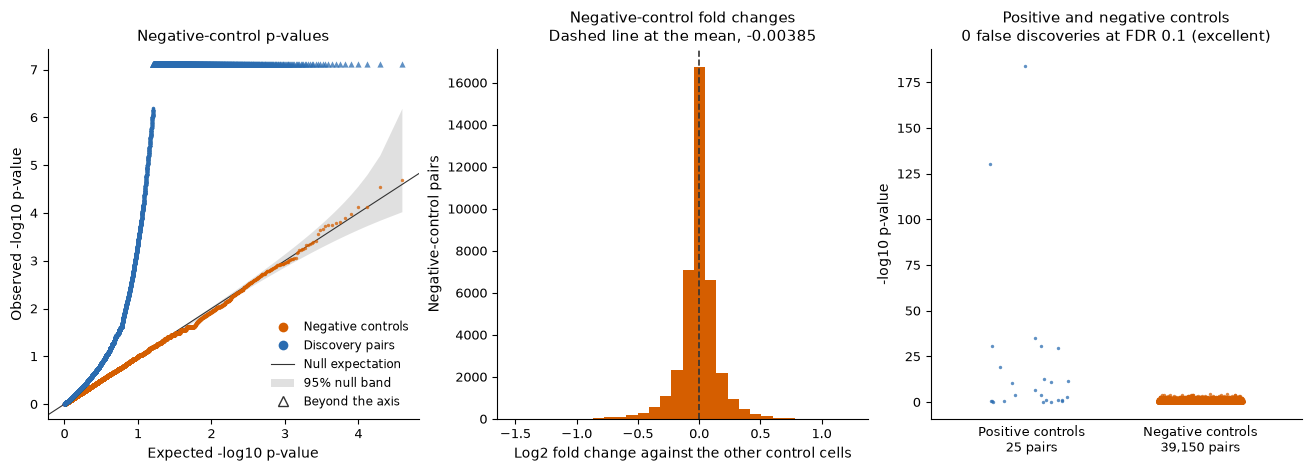

Started: 2026-10-30T22:02:13.809062Z | Wall time: 0.730 s

In [29]:
# Plot the calibration of the tests on the negative and positive controls.
ds.plots.association_calibration(tests)

The positive controls measure power. Most knockouts lower their own gene; IFNGR1 does not, as its efficiency showed.

In [30]:
# Show each target's test against its own gene, strongest decrease first.
columns = ["target", "n_cells", "z", "log2_fold_change", "p_value", "significant"]
result.positive.dropna(subset=["z"]).sort_values("z")[columns].round(3)

,target,n_cells,z,log2_fold_change,p_value,significant
12,JAK2,908,-24.198,-1.825,0.000,True
20,STAT1,399,-22.930,-2.119,0.000,True
9,IFNGR2,1122,-12.156,-0.428,0.000,True
5,CMTM6,779,-11.144,-0.457,0.000,True
21,STAT2,619,-11.098,-0.727,0.000,True
25,UBE2L6,489,-10.741,-0.416,0.000,True
22,STAT3,457,-8.580,-0.487,0.000,True
15,NFKBIA,708,-7.307,-0.538,0.000,True
24,TNFRSF14,907,-7.009,-0.315,0.000,True
10,IRF1,997,-6.660,-0.166,0.000,True


Started: 2026-10-30T22:02:14.540937Z | Wall time: 0.014 s

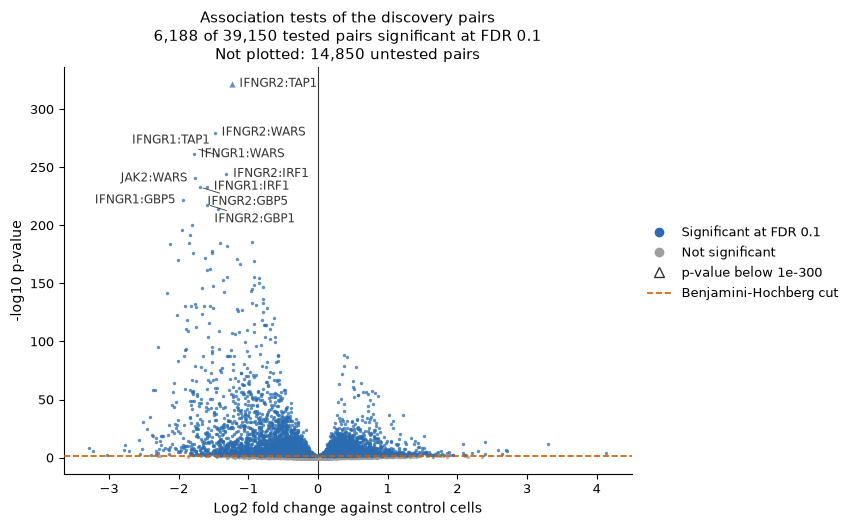

Started: 2026-10-30T22:02:14.556307Z | Wall time: 0.648 s

In [31]:
# Plot the fold change and p-value of every tested pair.
ds.plots.association_volcano(tests)

The strongest effects belong to the IFN-γ pathway: cells without IFNGR1, IFNGR2 or JAK2 lose interferon-induced genes such as TAP1, WARS and GBP5.

In [32]:
# Count each target's discoveries.
found = result.discovery.query("significant").groupby("target").size()
found.sort_values(ascending=False).rename("Discoveries").to_frame().T

target,IFNGR2,IFNGR1,JAK2,SMAD4,STAT1,IRF1,BRD4,CUL3,STAT2,MYC,...,MARCH8,STAT3,PDCD1LG2,IRF7,CAV1,ATF2,STAT5A,UBE2L6,CD86,CMTM6
Discoveries,927,899,892,872,738,603,255,247,163,93,...,31,31,27,27,26,25,25,23,22,20


Started: 2026-10-30T22:02:15.206319Z | Wall time: 0.013 s

## Group perturbations by their effects

`perturbation.profiles` averages, for each target, the expression of its cells over the variable genes, as z-scores against the control cells of each replicate [@Replogle_2022]. `perturbation.cluster` then groups targets whose profiles correlate. Cluster only targets with a clear effect, since flat profiles correlate by chance: here the 13 targets whose E-distance is significant. The default smallest cluster, 4, suits screens of hundreds of genes; with 13 targets, allow groups of 3.

In [33]:
# Profile each target over the variable genes, against each replicate's controls.
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    profiles = ds.perturbation.profiles(
        labels, rna["highly_variable_features"], sample_column="replicate"
    )

# Print the targets with too few cells to profile.
for warning in caught:
    print(warning.message)

# Cluster the targets with a significant E-distance.
strong = sorted(distances.query("adjusted_p_value <= 0.05")["target"])
clusters = ds.perturbation.cluster(profiles, perturbations=strong, min_cluster_size=3)
grouped = ds.perturbation.load_clusters(clusters)

# Show each target's cluster and membership probability, by cluster.
order = grouped.table.sort_values(["cluster", "probability"], ascending=[True, False])
order[["cluster", "probability", "n_cells"]].round(2)

2 of 27 targets have fewer than 25 cells and get no profile: 'CD274' (2), 'eGFP' (0). perturbation.load_profiles lists them all in left_out.


,cluster,probability,n_cells
perturbation,,,
SPI1,-1,0.00,45
BRD4,0,1.00,333
CUL3,0,1.00,239
MYC,0,1.00,96
IFNGR1,1,1.00,1078
IFNGR2,1,1.00,1122
JAK2,1,1.00,908
STAT1,1,0.51,399
STAT2,1,0.09,619


Started: 2026-10-30T22:02:15.221219Z | Wall time: 5.167 s

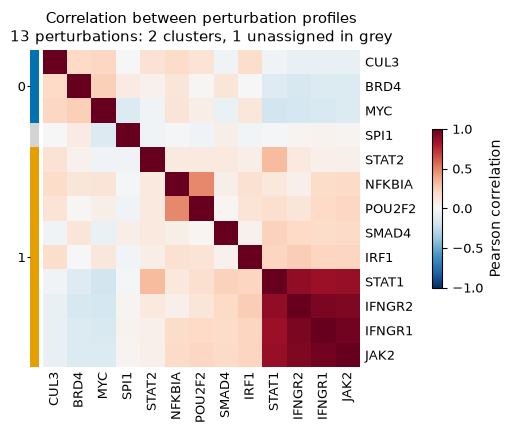

Started: 2026-10-30T22:02:20.389993Z | Wall time: 0.614 s

In [34]:
# Plot the correlations between the profiles, ordered by similarity.
ds.plots.perturbation_clusters(clusters)

IFNGR1, IFNGR2 and JAK2 form one cluster, with STAT1 at its edge: the IFN-γ receptor and the signalling genes downstream of it. BRD4, CUL3 and MYC, whose knockouts raised PD-L1, form another. IRF1, SMAD4, STAT2, NFKBIA and POU2F2 join the first cluster with low probability, and SPI1 stays unassigned (-1). The paper's analysis of perturbation signatures also grouped IFNGR1, IFNGR2, JAK2 and STAT1, and set IRF1 apart. Read a cluster as a hypothesis of shared function, and check it against the pathway it implies.

## Collect one row per target

Join the numbers of each step into one table: cells, remaining expression of the target gene, E-distance, KO share, PD-L1 shift of the KO cells, discoveries and cluster.

In [35]:
# Join one row per target from each step's table.
effects = measured.set_index("target")[["n_cells", "remaining_fraction"]]
effects["edistance"] = distances.set_index("target")["edistance"]
effects["ko_share"] = targets_table["ko_share"]
effects["pdl1_ko_shift"] = [
    shift.get(f"{target} KO", np.nan) for target in effects.index
]
effects["discoveries"] = found.reindex(effects.index, fill_value=0)
effects["cluster"] = grouped.table["cluster"].reindex(effects.index).astype("Int64")

# Show the targets with at least 25 cells, by E-distance.
effects.query("n_cells >= 25").sort_values("edistance", ascending=False).round(2)

,n_cells,remaining_fraction,edistance,ko_share,pdl1_ko_shift,discoveries,cluster
target,,,,,,,
STAT1,399,0.21,358.53,0.77,-0.43,738,1
JAK2,908,0.21,264.95,0.80,-0.50,892,1
IFNGR1,1078,1.04,252.63,0.81,-0.49,899,1
IFNGR2,1122,0.67,237.71,0.76,-0.49,927,1
SMAD4,586,0.68,162.45,0.84,-0.03,872,1
IRF1,997,0.85,76.41,0.69,-0.21,603,1
SPI1,45,0.66,63.65,0.47,-0.11,76,-1
CUL3,239,0.64,55.00,0.36,0.48,247,0
MYC,96,1.19,31.14,0.26,0.60,93,0


Started: 2026-10-30T22:02:21.006402Z | Wall time: 0.020 s

## Run the analysis as one recipe

`ds.pipeline.perturbation` runs the same steps as one durable run: guide calling, labels, efficiency, E-distances, the signature and Mixscape, the association tests, and the profiles and their clusters. Give it the RNA run as `cells` with that run's settings, so that it uses the run's cells, variable genes and PCA, and the settings used above. When Mixscape runs, the recipe profiles each target's knocked-out cells unless `profiles` sets `"cells": "labelled"`, which profiles every labelled cell as above. Every step matches a call above, so the run reuses the saved results and computes nothing.

In [36]:
# Run the screen's analysis as one recipe; the run's report keeps its warnings.
with warnings.catch_warnings(record=True):
    warnings.simplefilter("always")
    screen = ds.pipeline.perturbation(
        cells=rna,
        labels={"controls": ["NT"]},
        hvg={"top_n": 2000},
        pca={"dims": 40},
        signature={"dims": 40, "sample_column": "replicate"},
        mixscape=True,
        associations={"sample_column": "replicate"},
        profiles={"sample_column": "replicate", "cells": "labelled"},
        clusters={"perturbations": strong, "min_cluster_size": 3},
        label="screen",
    )

# Show each stage's status and how many of its outputs it reused.
report = screen.report()
pd.DataFrame(
    [
        {
            "Stage": stage["stage"],
            "Status": stage["status"],
            "Outputs": len(stage["outputs"]),
            "Reused": sum(output["reused"] for output in stage["outputs"]),
        }
        for stage in report["stages"]
    ]
).set_index("Stage")

,Status,Outputs,Reused
Stage,,,
input_snapshot,completed,3,3
filtering,skipped,0,0
guide_calling,completed,2,2
perturbation_labels,completed,1,1
efficiency,completed,1,1
highly_variable_features,completed,1,1
normalization,completed,1,1
pca,completed,1,1
harmony,skipped,0,0


Started: 2026-10-30T22:02:21.028434Z | Wall time: 1.376 s

The run's cell view holds each cell's guide call, perturbation label and Mixscape class, frozen with the run.

In [37]:
# Show the first cells' guide call, label, control flag and Mixscape class.
fields = ["guide_call", "perturbation_label", "is_control", "mixscape_class"]
screen.cells.to_pandas_dataframe(["ids", *fields]).head()

,ids,guide_call,perturbation_label,is_control,mixscape_class
0,l1_AAACCTGAGCCAGAAC,STAT2g2,STAT2,False,STAT2 KO
1,l1_AAACCTGAGTGGACGT,CAV1g4,CAV1,False,CAV1 NP
2,l1_AAACCTGCATGAGCGA,STAT1g2,STAT1,False,STAT1 KO
3,l1_AAACCTGTCTTGTCAT,CD86g1,CD86,False,CD86 NP
4,l1_AAACGGGAGAACAACT,IRF7g2,IRF7,False,IRF7 NP


Started: 2026-10-30T22:02:22.406593Z | Wall time: 0.095 s

Each stage records a summary with the numbers to check before reading results, in the same order as the steps above.

In [38]:
# Show the summaries of the stages that make the screen's decisions.
summaries = {stage["stage"]: stage["summary"] for stage in report["stages"]}
for name in (
    "guide_calling",
    "perturbation_labels",
    "efficiency",
    "edistance",
    "mixscape",
    "associations",
    "profiles",
    "perturbation_clusters",
):
    print(name, summaries[name])

# Print the warnings that the run recorded, with the stage that raised each one.
for warning in report["summary"]["warnings"]:
    print(warning["stage"], warning["message"])

guide_calling {'guide_thresholds': {'samples': 1, 'guides': 111, 'statuses': {'fitted': 107, 'no_cells': 1, 'too_sparse': 2, 'no_fit': 1, 'no_positive': 0}}, 'guide_calls': {'cells': 20729, 'negative': 593, 'single': 18330, 'multiple': 1806, 'calledGuides': 107}}
perturbation_labels {'cells': 20729, 'controls': 2164, 'negative': 593, 'multipleTargets': 1397, 'targets': 27, 'targetCells': {'min': 0, 'median': 611.0, 'max': 1122}, 'fewCellTargets': {'eGFP': 0, 'CD274': 2}, 'fewCellTargetCount': 2}
efficiency {'by': 'target', 'rows': 27, 'statuses': {'tested': 26, 'no_feature': 0, 'no_cells': 1, 'no_control_expression': 0}, 'knockedDown': 17, 'medianRemainingFraction': 0.7446, 'noFeature': []}
edistance {'by': 'target', 'rows': 27, 'statuses': {'tested': 26, 'too_few_cells': 1}, 'significant': 13, 'atFloor': 13, 'nPermutations': 1000}
mixscape {'rows': 26, 'statuses': {'fitted': 11, 'few_de_genes': 15, 'few_cells': 0, 'no_fit': 0}, 'cells': 16575, 'knockedOut': 4705, 'fewDeGenes': ['ATF2'

Started: 2026-10-30T22:02:22.502926Z | Wall time: 0.005 s

## Test effects across replicates

Cells from one experiment are not independent replicates, so a claim that a perturbation changes a gene in general needs a test across replicates. Sum each gene's counts per target and replicate with `compare.compute_bulk`, leaving out the `Negative` and `Multiple` cells. [CytePool](https://docs.nygen.io/CytePool/) tests such pseudobulk profiles of each target against the control cells with limma, edgeR or DESeq2.

In [39]:
# Sum each gene's counts per target and replicate.
pseudobulk = ds.compare.compute_bulk(
    labels,
    from_assay="RNA",
    secondary_groups="replicate",
    aggr_type="sum",
    feature_label="name",
    null_vals=["Negative", "Multiple"],
)

# Show a corner of the table: genes as rows, a target and replicate in each column.
pseudobulk.iloc[:5, :6]

,ATF2_rep1-tx,ATF2_rep3-tx,ATF2_rep4-tx,BRD4_rep1-tx,BRD4_rep3-tx,BRD4_rep4-tx
AL627309.1,3,5,5,2,1,1
AP006222.2,27,18,17,1,10,2
RP4-669L17.10,2,2,3,0,0,0
RP11-206L10.3,2,1,5,2,0,1
RP11-206L10.2,12,6,7,2,3,4


Started: 2026-10-30T22:02:22.509217Z | Wall time: 2.330 s

## Common mistakes and limitations

- Counting ambient guide molecules as calls: every cell holds a few molecules of guides it does not carry. Call guides with a fitted threshold, inspect the fits with `plots.guide_thresholds`, and read the share of cells with several guides, which a low-MOI screen keeps small.
- Fitting thresholds per lane or GEM group without enough cells: a fit needs cells that carry the guide in each sample. Compare the calls before choosing `sample_column`.
- Treating `Negative` cells as controls: controls are the cells that carry control guides only, which `perturbation.labels` names from the targets in `controls`.
- Reading a remaining fraction near 1 as a failed knockout: Cas9 edits lower transcripts mainly through nonsense-mediated decay. Read the E-distance, Mixscape's classes and the association tests too.
- Reporting a target with no Mixscape KO cells as having no effect: Mixscape sees changes of the transcriptome only, as CMTM6's lower PD-L1 protein shows.
- Reading discoveries before the calibration check: a `moderate` or `severe` grade means the test is miscalibrated for the screen, and its discoveries are not trustworthy until the cause is fixed.
- Treating cells as replicates: test effects across replicates with pseudobulk profiles before claiming them in general.

The [Perturbation API reference](/api/perturbation.html) explains every `ds.perturbation` method, its checks and the records that its loaders return.